In [191]:
#%%
import math
import numpy as np
import inspect
import importlib

import scipy.interpolate

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.pyplot as plt

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 16

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.offline import plot
pio.renderers.default = "svg"

import sys
import os
parent_directory = os.path.dirname(os.getcwd())
sys.path.append(parent_directory)
#parent_directory = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
#sys.path.append(parent_directory)
 
import IoT_node_models 
from IoT_node_models import *

path_to_save_svg = "Saved_Data"



In [192]:

#importlib.reload(IoT_node_models)
#from IoT_node_models import *

In [193]:
footprintStructure = FootprintStructure(("GWP", "Money"), units=("$kgCO_2 eq.$", "EUR"))

In [194]:

#component_List_3V3 = [apollo_component_3V3,radio_component_3V3,bme_component_3V3]
radio_component_3V3 .set_factors(footprintStructure.vector(GWP=(0.2262, 0.517, 0.5817)  , Money=5.3))   # SX1276 : 5.3
bme_component_3V3   .set_factors(footprintStructure.vector(GWP=(0.0539, 0.0539, 0.5561) , Money=6.94)) 
apollo_component_3V3.set_factors(footprintStructure.vector(GWP=(0.366, 0.366, 0.4537)   , Money=3.65))   # Apollo3: 3.65
    

In [195]:
# Footprint factors: GWP is (low, mid, high), Money is a fixed value
this_LDO = LDO(name = "Node LDO", category = "Power_supply", v_out = 3.3, i_q = 1e-3, v_in = 3.3, component_list = component_List_3V3,
                factors = footprintStructure.vector(GWP=(0.0446, 0.132, 0.1751), Money=0.228))     # XC6206 : 0.228 + Diode and Transistor?


AA_series = 3
AA_footprint = 0.165
AA_cost      = 0.25 
Batt_footprint = AA_series*AA_footprint
Batt_cost      = AA_series*AA_cost

this_Batt= Battery(name = "Node Batt.", category = "Battery", v = 3.3, capacity_mAh = 1800, i = 0, selfdischarge_p_year = 5,
                   factors = footprintStructure.vector(GWP=(Batt_footprint  ,Batt_footprint,Batt_footprint), Money=Batt_cost))


In [196]:
this_hw = Hardware(name= "IoT Node",footprintStructure=footprintStructure, categories=DEFAULT_CATEGORIES)
for comp in component_List_3V3:
    this_hw.add(comp)
this_hw.add(this_LDO)
this_hw.add(this_Batt)

In [197]:

this_profile= LoRa_Profile("Profile", this_hw,  RX_state=radio_state_RX_3V3,TX_state=radio_state_TX_3V3,
                    P_TX= PTX_PABOOST_3V3, I_TX=I_PABoost_3V3 ) 
             

In [198]:

this_task_tx0 = this_profile.create_task_tx(name="TX-0", Ptx = 17,SF=7 ,Coding=1,Header=True,DE = 1,BW = 125e3, Payload = 50, TX_rate=24*1)
this_task_rx0 = this_profile.create_task_rx(name="RX-0", RX_rate=2, RX_duration=0.250 )

this_profile.add_task(task_TPHG_3V3,24*12)

In [199]:
this_hw.add(Component(name="Casing", category="Casing",   factors=footprintStructure.vector(GWP=(0.3932, 0.709,  1.3259), Money=10)))
this_hw.add(Component(name="EoL",    category="EoL",      factors=footprintStructure.vector(GWP=(0.0388, 0.0812, 0.1201), Money=0)))
this_hw.add(Component(name="Others", category="Others",   factors=footprintStructure.vector(GWP=(0.0546, 0.0938, 0.1394), Money=1.42)))
this_hw.add(Component(name="PCB",    category="PCB",      factors=footprintStructure.vector(GWP=(0.9403, 1.17,   1.5696), Money=1.17)))
this_hw.add(Component(name="UI",     category="UI",       factors=footprintStructure.vector(GWP=(0.0017, 0.0306, 0.1155), Money=0.54)))

In [200]:

this_node = Node_description(name="My_node",hardware=this_hw,profile=this_profile)


In [201]:
def PL_model(d):
    return path_loss_PLd0(d=d, PLd0=94.40,d0=1, n=2.03)

this_task_tx0.set_Path_loss_model(PL_model)

-------------------------------------------------
            Tasks summary                        
-------------------------------------------------
Task name            : TX-0           RX-0           TPHG meas.     Sleep          
Times/day    [1/d]   : 24             2              288            1              
Tot. durat.  [s]     : 55.2468        0.5000         628.7988       0.0000         
Tot. en./d   [mJ]    : 21704.5529     18.6120        23482.7893     985.5316       
Node en./d   [mJ]    : 46191.4858      
-------------------------------------------------
-----------------------------------------------------------------
                        Module summary                           
-----------------------------------------------------------------
Component    State        Active [s]   Energy [mJ]  Av. Cur.[uA]  
Apollo3                   615.3607     1934.0443    6.7832641     
     -       Active       615.3607     1163.5856    
     -       Sleep        85784.6393   

c:\Users\Pol Maistriaux\Documents\Research\IoT_Node_Modeling\IoT_node_models\Node_description\Node_description.py:189: UserWarning: Mismatched number of handles and labels: len(handles) = 3 len(labels) = 8
  ax[1].legend([patches1[i] for i in indexModuleSleep],component_label, bbox_to_anchor=(1,0), bbox_transform=plt.gcf().transFigure, loc="lower right",fontsize = 12)


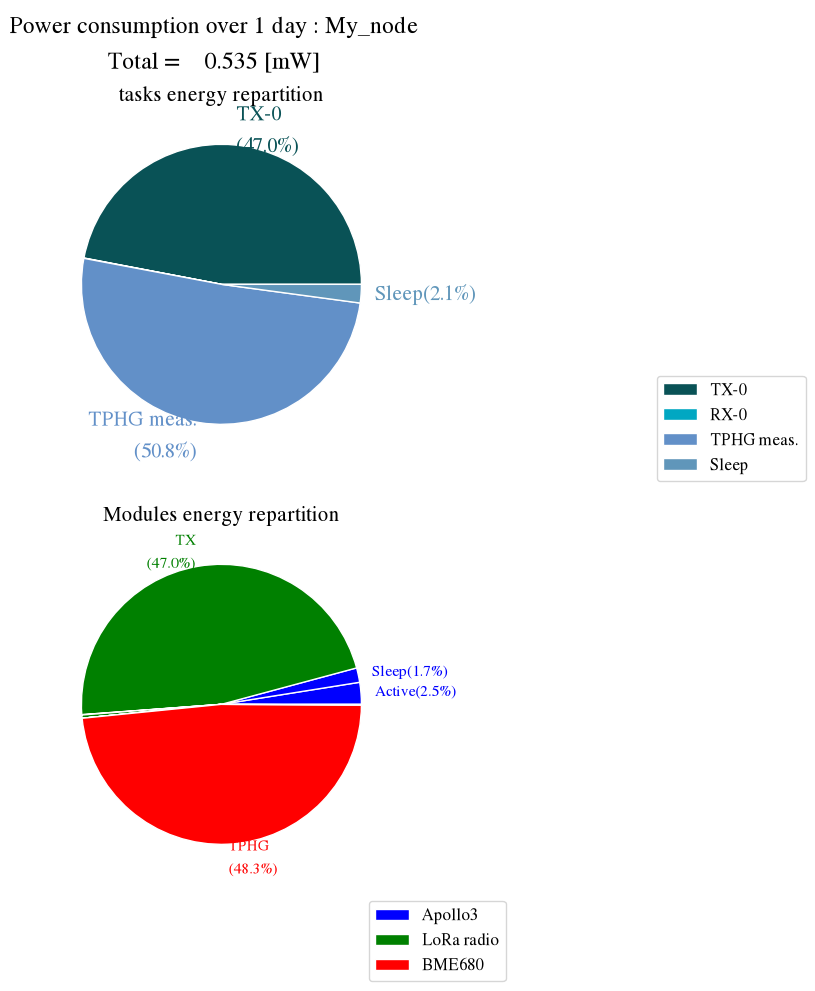

In [202]:
this_task_tx0.set_distance( d= 1500)
this_node.compute()
this_node.print_tasks()
this_node.print_components()
this_node.plot_power()

Category       GWP [$kgCO_2 eq.$]       Money [EUR]
-------------  -----------------------  -----------
Casing         [0.393, 0.709, 1.33]     10         
Connectivity   0                        0          
EoL            [0.0388, 0.0812, 0.12]   0          
Memory         0                        0          
Others         [0.0546, 0.0938, 0.139]  1.42       
PCB            [0.94, 1.17, 1.57]       1.17       
Power_supply   [0.0446, 0.132, 0.175]   0.228      
Processing     0                        0          
Sensing        0                        0          
UI             [0.0017, 0.0306, 0.116]  0.54       
Battery        0.495                    0.75       
Uncategorized  [0.646, 0.937, 1.59]     15.89      
-------------  -----------------------  -----------
Total          [2.61, 3.65, 5.53]       30         


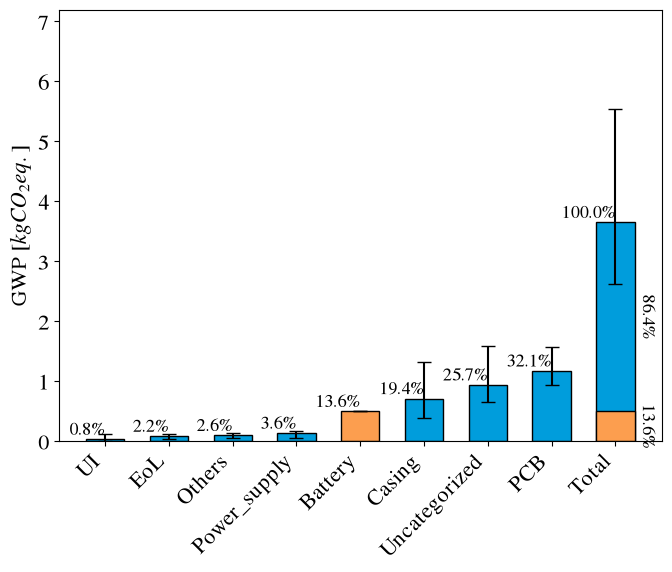

In [203]:

this_hw.compute_footprint()
this_hw.report_footprint()
this_hw.plot_footprint(label="GWP")

In [204]:

importlib.reload(IoT_node_models)
from IoT_node_models import *

Importing IoT Node models
Importing IoT Node description models
Importing IoT Node hardware models
Importing IoT Node profile models
Importing Wireless communication packages
Importing IoT Node deployment strategies
Importing custom components data


In [205]:

placementNnodes   = 100
decomNnodes       = 100
replacementNnodes = 10

placementTransport      = Transport(n_node=placementNnodes  , km_fixed=40, km_p_node=1, footprint_p_km=0.350, label="GWP")
decomTransport          = Transport(n_node=decomNnodes      , km_fixed=40, km_p_node=1, footprint_p_km=0.350, label="GWP")
replacementTransport    = Transport(n_node=replacementNnodes, km_fixed=40, km_p_node=1, footprint_p_km=0.350, label="GWP")

deploymentStart = DeploymentStrategy_wTransport( Nyears=10, replacementCategories=("Battery",),
                transport_placement     =placementTransport, 
                transport_replacement   =decomTransport, 
                transport_decom         =replacementTransport)

this_node.set_deployment_strategy(deploymentStart)
this_node.compute()

In [101]:
[res1,res2,lifetime,residue] =deployment_battery_replacement(
                                    Replacement_type = "Complete",
                                    Footprint=node_footprint,
                                    Node=node,
                                    Nyears= 20)
print([res1,res2,lifetime,residue])

[7.876600000000001, np.float64(7.3804069586404655), np.float64(1.7857793679015153), np.float64(0.5346236781463464)]


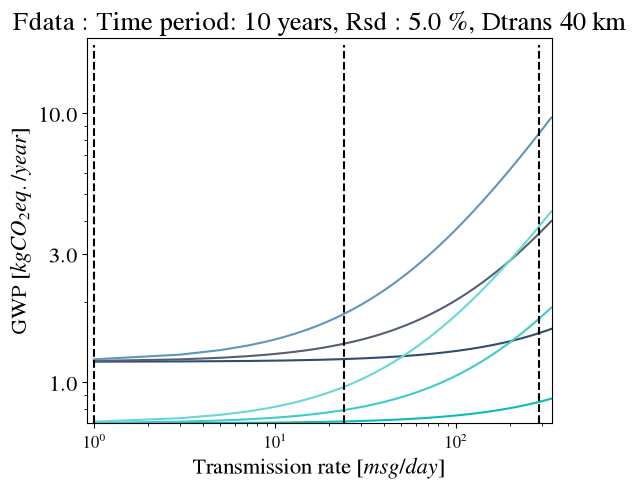

In [105]:

lora_deployment_sweep_fdata(Replacement_strategy = "Battery", 
                       Footprint=node_footprint,
                       Node=node,
                       Nyears=10,
                       dtrans=40,
                       nAA = [1,3]  , 
                       param = [200,700,1200]   , 
                       paramType ="dnode",
                       fmax=24*12+50, 
                       f_step=2         ,
                       Task_tx = this_task_tx0,
                       transport_model=F_trans, 
                       filename = None            ,figsize =(6,5) )

In [87]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


(0.1, 5.0)

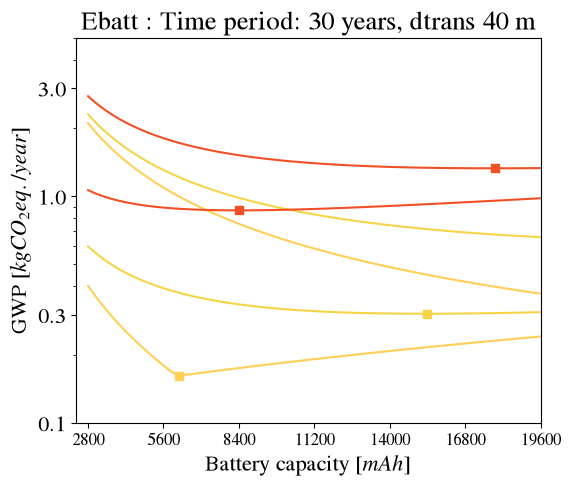

In [88]:

n_years = 30                       
km_trans = 40

node.change_task_rate(task_TPHG_3V3,24*12)
node.change_task_rate(this_task_tx0,24)
this_task_tx0.set_distance(d= 700)

fig , ax = deployment_sweep_ebatt(Replacement_strategy = "Complete", 
                       Footprint=node_footprint,
                       Node=node,
                       Nyears=n_years,
                       dtrans=km_trans,
                       param = [0,3,10] , 
                       paramType ="rsd",
                       nAAmin = 1, 
                       nAAmax=7, 
                       nAA_step=0.1 ,
                       transport_model=F_trans, 
                       filename = None      ,figsize =(6,5) )


node.change_task_rate(task_TPHG_3V3,0)
node.change_task_rate(task_TPH_3V3 ,24*12)

fig , ax = deployment_sweep_ebatt(Replacement_strategy = "Complete", 
                       Footprint=node_footprint,
                       Node=node,
                       Nyears=n_years,
                       dtrans=km_trans,
                       param = [0,3,10] , 
                       paramType ="rsd",
                       nAAmin = 1, 
                       nAAmax=7, 
                       nAA_step=0.1 ,
                       transport_model=F_trans, 
                       filename = None      ,figsize =(6,5) , figAppend=[fig,ax])

ax.set_ylim(ymin = 0.1)
ax.set_ylim(ymax = 5)

(<Figure size 600x500 with 1 Axes>,
 <Axes: title={'center': 'Ebatt : Time period: 30 years, dtrans 40 m'}, xlabel='Battery capacity [$mAh$]', ylabel='GWP [$kgCO_2eq./year$]'>)

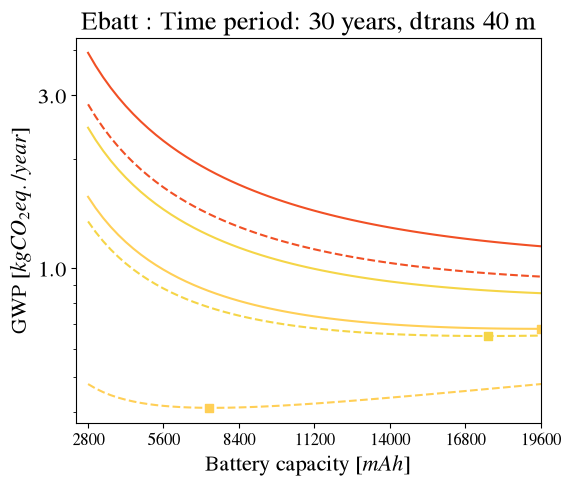

In [92]:

n_years = 30                       
km_trans = 40

node.change_task_rate(task_TPHG_3V3,24*12)
this_task_tx0.set_distance(d= 700)

deployment_sweep_ebatt(Replacement_strategy = "Both", 
                       Footprint=node_footprint,
                       Node=node,
                       Nyears=n_years,
                       dtrans=km_trans,
                       param = [5,40,100] , 
                       paramType ="dtrans",
                       nAAmin = 1, 
                       nAAmax=7, 
                       nAA_step=0.1 ,
                       transport_model=F_trans, 
                       filename = None      ,figsize =(6,5) )
    